Day 8 — CCSD, Correlation & Block2

1. Scientific Goal

In Day 7, we studied the H₂ potential energy curve using Hartree–Fock.

In Day 8, we investigated how the correlation correction changes as the H–H bond is stretched.

Workflow:

H₂ geometry → RHF → CCSD → correlation energy → bond stretching → Block2

---

2. CCSD

Hartree–Fock approximates the wavefunction using a single Slater determinant and does not capture the full electron correlation.

CCSD improves the description by including single and double excitations.

The energy relation is:

E_CCSD = E_HF + E_corr

where:

- E_HF = Hartree–Fock energy
- E_corr = correlation energy
- E_CCSD = total CCSD energy

---

3. H₂ Results

Calculations were performed using:

- Molecule: H₂
- Basis: STO-3G
- Charge: 0
- Spin: 0
- Distance unit: Bohr

R (Bohr)| HF (Eh)| CCSD (Eh)| E_corr (Eh)
1.0| −1.06599946| −1.07896981| −0.01297034
1.4| −1.11671433| −1.13727611| −0.02056178
1.8| −1.07898221| −1.11084598| −0.03186377
2.2| −1.01648572| −1.06473935| −0.04825363

Observation

Over the sampled bond lengths:

R ↑ → |E_corr| ↑

The magnitude of the correlation correction becomes larger as the H–H bond is stretched.

---

4. Correlation vs. Entanglement

The result above demonstrates stronger correlation effects relative to the HF reference.

However, it does not directly demonstrate increasing entanglement.

To study entanglement, we need to analyze the many-body wavefunction through:

Many-body wavefunction → bipartition → Schmidt decomposition → Schmidt coefficients → entanglement measures

This will be addressed in later stages of the project.

---

5. Block2

Block2 is a specialized quantum chemistry package for tensor-network and DMRG calculations.

In Day 8:

- Block2 was successfully installed.
- "import block2" was successful.
- The Colab environment is ready for Block2-based calculations.

---

6. Connection to Previous Days

Day 5:
SVD → Schmidt coefficients → Entanglement → MPS

Day 6:
MPS → Variational optimization → DMRG

Day 7:
H₂ → RHF → Potential Energy Curve → Bond stretching

Day 8:
H₂ → RHF → CCSD → Correlation → Block2

---

Mental Map

H₂ stretching → stronger correlation correction → many-body wavefunction → Schmidt spectrum → entanglement → MPS/DMRG

Key Result

For H₂ with the STO-3G basis, the magnitude of the CCSD correlation-energy correction increased over the sampled H–H bond lengths. This provides a bridge from conventional quantum chemistry to the many-body and entanglement analysis that follows.

In [1]:
!pip install pyscf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 11.8 MB/s eta 0:00:00


In [2]:
from pyscf import gto

mol = gto.M(
    atom='''
    H  0  0  0
    H  0  0  1.4
    ''',
    basis='sto-3g',
    charge=0,
    spin=0,
    unit='Bohr'
    )

print("Atoms:", mol.natm)
print("Electrons:", mol.nelectron)
print("Basis functions:", mol.nao_nr())

Atoms: 2
Electrons: 2
Basis functions: 2


In [3]:
from pyscf import scf

mf = scf.RHF(mol)
energy_hf = mf.kernel()

print("HF energy:", energy_hf)

converged SCF energy = -1.11671432506255
HF energy: -1.116714325062551


In [4]:
from pyscf import cc

mycc = cc.CCSD(mf)

print(mycc)

In [5]:
energy_corr, t1, t2 = mycc.kernel()
energy_ccsd = energy_hf + energy_corr

print("CCSD correlation energy:", energy_corr)
print("CCSD total energy:", energy_ccsd)

E(CCSD) = -1.137276108862316  E_corr = -0.02056178379976508
CCSD correlation energy: -0.020561783799765077
CCSD total energy: -1.1372761088623162


In [21]:
from pyscf import gto, scf, cc

bond_lengths = [1.0, 1.4, 1.8, 2.2]

results = []

for R in bond_lengths:
    mol = gto.M(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis="sto-3g",
        charge=0,
        spin=0,
        unit="Bohr",
        verbose=0
    )

    mf = scf.RHF(mol)
    energy_hf = mf.kernel()

    mycc = cc.CCSD(mf)
    energy_corr, t1, t2 = mycc.kernel()
    energy_ccsd = energy_hf + energy_corr

    results.append((R, energy_hf, energy_ccsd, energy_corr))

    print(
        f"R = {R:.1f} Bohr | "
        f"HF = {energy_hf:.8f} Eh | "
        f"CCSD = {energy_ccsd:.8f} Eh | "
        f"Correlation = {energy_corr:.8f} Eh"
    )

print("Number of results:", len(results))

R = 1.0 Bohr | HF = -1.06599946 Eh | CCSD = -1.07896981 Eh | Correlation = -0.01297034 Eh
R = 1.4 Bohr | HF = -1.11671433 Eh | CCSD = -1.13727611 Eh | Correlation = -0.02056178 Eh
R = 1.8 Bohr | HF = -1.07898221 Eh | CCSD = -1.11084598 Eh | Correlation = -0.03186377 Eh
R = 2.2 Bohr | HF = -1.01648572 Eh | CCSD = -1.06473935 Eh | Correlation = -0.04825363 Eh
Number of results: 4


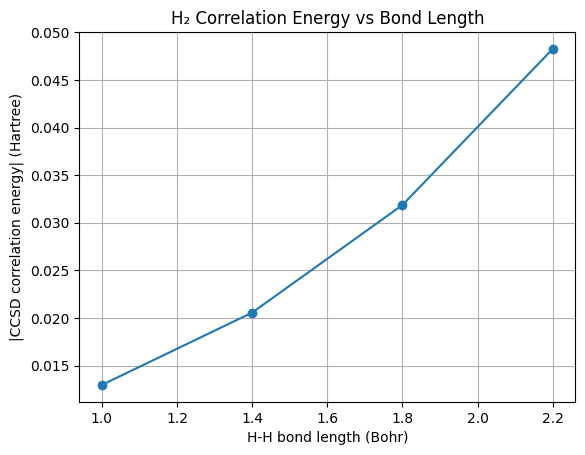

In [22]:
import matplotlib.pyplot as plt

bond_lengths = [row[0] for row in results]
correlation_energy = [row[3] for row in results]

plt.plot(
    bond_lengths,
    [abs(E) for E in correlation_energy],
    marker="o"
)

plt.xlabel("H-H bond length (Bohr)")
plt.ylabel("|CCSD correlation energy| (Hartree)")
plt.title("H₂ Correlation Energy vs Bond Length")
plt.grid(True)
plt.show()

In [16]:
!pip install block2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.8/124.8 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.5/195.5 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 3.0 MB/s eta 0:00:00
  Attempting uninstall: tbb
    Found existing installation: tbb 2022.3.1
    Uninstalling tbb-2022.3.1:
      Successfully uninstalled tbb-2022.3.1
  Attempting uninstall: onemkl-license
    Found existing installation: onemkl-license 2025.3.1
    Uninstalling onemkl-license-2025.3.1:
      Successfully uninstalled onemkl-license-2025.3.1
  Attempting uninstall: mkl
    Found existing installation: mkl 2025.3.1
    Uninstalling mkl-2025.3.1:
      Successfully uninstalled mkl-2025.3.1


In [17]:
import block2

print("Block2 imported successfully!")

Block2 imported successfully!


In [18]:
from block2 import SU2

print("Block2 is ready!")

Block2 is ready!
